##Czyszczenie danych

---



In [ ]:
import pandas as pd


df_airbnb = pd.read_csv('/content/Airbnb_Open_Data.csv')
df_airbnb

/tmp/ipykernel_2013/782342667.py:4: DtypeWarning: Columns (25) have mixed types. Specify dtype option on import or set low_memory=False.
  df_airbnb = pd.read_csv('/content/Airbnb_Open_Data.csv')


,id,NAME,host id,host_identity_verified,host name,neighbourhood group,neighbourhood,lat,long,country,...,service fee,minimum nights,number of reviews,last review,reviews per month,review rate number,calculated host listings count,availability 365,house_rules,license
0,1001254,Clean & quiet apt home by the park,80014485718,unconfirmed,Madaline,Brooklyn,Kensington,40.64749,-73.97237,United States,...,$193,10.0,9.0,10/19/2021,0.21,4.0,6.0,286.0,Clean up and treat the home the way you'd like...,NaN
1,1002102,Skylit Midtown Castle,52335172823,verified,Jenna,Manhattan,Midtown,40.75362,-73.98377,United States,...,$28,30.0,45.0,5/21/2022,0.38,4.0,2.0,228.0,Pet friendly but please confirm with me if the...,NaN
2,1002403,THE VILLAGE OF HARLEM....NEW YORK !,78829239556,NaN,Elise,Manhattan,Harlem,40.80902,-73.94190,United States,...,$124,3.0,0.0,NaN,NaN,5.0,1.0,352.0,"I encourage you to use my kitchen, cooking and...",NaN
3,1002755,NaN,85098326012,unconfirmed,Garry,Brooklyn,Clinton Hill,40.68514,-73.95976,United States,...,$74,30.0,270.0,7/5/2019,4.64,4.0,1.0,322.0,NaN,NaN
4,1003689,Entire Apt: Spacious Studio/Loft by central park,92037596077,verified,Lyndon,Manhattan,East Harlem,40.79851,-73.94399,United States,...,$41,10.0,9.0,11/19/2018,0.10,3.0,1.0,289.0,"Please no smoking in the house, porch or on th...",NaN
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
102594,6092437,Spare room in Williamsburg,12312296767,verified,Krik,Brooklyn,Williamsburg,40.70862,-73.94651,United States,...,$169,1.0,0.0,NaN,NaN,3.0,1.0,227.0,No Smoking No Parties or Events of any kind Pl...,NaN
102595,6092990,Best Location near Columbia U,77864383453,unconfirmed,Mifan,Manhattan,Morningside Heights,40.80460,-73.96545,United States,...,$167,1.0,1.0,7/6/2015,0.02,2.0,2.0,395.0,House rules: Guests agree to the following ter...,NaN
102596,6093542,"Comfy, bright room in Brooklyn",69050334417,unconfirmed,Megan,Brooklyn,Park Slope,40.67505,-73.98045,United States,...,$198,3.0,0.0,NaN,NaN,5.0,1.0,342.0,NaN,NaN
102597,6094094,Big Studio-One Stop from Midtown,11160591270,unconfirmed,Christopher,Queens,Long Island City,40.74989,-73.93777,United States,...,$109,2.0,5.0,10/11/2015,0.10,3.0,1.0,386.0,NaN,NaN


In [ ]:
# sprawdzenie jaki procent wartości pustych występuje w każdej kolumnie(żeby wiedzieć gdzie lepiej pozbyć się nulli a gdzie np całej kolumny)
print(df_airbnb.isnull().sum()/len(df_airbnb))

id                                0.000000
NAME                              0.002437
host id                           0.000000
host_identity_verified            0.002817
host name                         0.003957
neighbourhood group               0.000283
neighbourhood                     0.000156
lat                               0.000078
long                              0.000078
country                           0.005185
country code                      0.001277
instant_bookable                  0.001023
cancellation_policy               0.000741
room type                         0.000000
Construction year                 0.002086
price                             0.002407
service fee                       0.002661
minimum nights                    0.003986
number of reviews                 0.001784
last review                       0.154904
reviews per month                 0.154768
review rate number                0.003177
calculated host listings count    0.003109
availabilit

In [ ]:
 #czyszczenie znaków specjalnych, zmiana typu zmiennej z tekstowej na zmiennoprzecinkową
df_airbnb["price"] = df_airbnb["price"].str.replace(r'[$,]',"", regex=True).astype(float)
df_airbnb["service fee"] = df_airbnb["service fee"].str.replace(r'[$,]',"", regex=True).astype(float)

In [ ]:
# czyszczenie wartości pustych  w cenie, jako że jest to główna wartość podlegająca analizom jej brak automatycznie sprawia, że rekord jest bezużyteczny.
# decyduje się zdropować puste rekordy gdyż nie ma podstaw by spekulować  o cenie.
df_airbnb =df_airbnb.dropna(subset=["price"])

In [ ]:
# sprawdzenie minimalnej wartości service fee, aby zobaczyć czy 0 jest wpisywane, czy można założyć że brak informacji = 0
df_airbnb['service fee'].min()


10.0

In [ ]:
# w związku że wartość minimalna service fee to 10$ zakładam, że brak informacji oznacza brak dodatkowych opłat
df_airbnb["service fee"] = df_airbnb["service fee"].fillna(0)

/tmp/ipykernel_2013/3218000491.py:2: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  df_airbnb["service fee"] = df_airbnb["service fee"].fillna(0)


In [ ]:
#sprawdzenie wartości availability 365 w celu wykluczenia niepoprawnych rekordów
df_airbnb['availability 365'].agg(['min', 'max'])



,availability 365
min,-10.0
max,3677.0


In [ ]:
# ograniczenie minimalnej i maksymalnej wartości availability 365 do przedziału 0 - 365
df_airbnb['availability 365'] = df_airbnb['availability 365'].clip(lower= 0, upper = 365)

/tmp/ipykernel_2013/2190258462.py:2: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  df_airbnb['availability 365'] = df_airbnb['availability 365'].clip(lower= 0, upper = 365)


In [ ]:
# pozbycie się całej kolumnny license, która w 99% jest pusta przez co nie nadaje się do analizy
df_airbnb = df_airbnb.drop('license', axis = 1)

In [ ]:
# zmiana kolumny house_rules na boolean, w związku z dużą dowolnością i brakiem powtarzalnych wartości uznałem, że ewentualnie przydatne do analizy może być rozróżnienie czy są jakieś szczególne obostrzenia, czy ich nie ma
# rozważałem jeszcze wyszukanie kluczowych fraz np "no pets" "pets allowed" i rozróżnianie na podstawie polityki wobec zwierzaków.
df_airbnb['house_rules'] = df_airbnb['house_rules'].notna()

In [ ]:
# sprawdzenie unikalnych wartości w kolumnie czy np nie ma osobnych rekordów dla "Brooklyn" i "brooklyn"
df_airbnb['neighbourhood group'].unique()


array(['Brooklyn', 'Manhattan', 'brookln', 'manhatan', 'Queens', nan,
       'Staten Island', 'Bronx'], dtype=object)

In [ ]:
# j.w
df_airbnb['neighbourhood'].unique()

array(['Kensington', 'Midtown', 'Harlem', 'Clinton Hill', 'East Harlem',
       'Murray Hill', 'Bedford-Stuyvesant', "Hell's Kitchen",
       'Upper West Side', 'Chinatown', 'South Slope', 'West Village',
       'Williamsburg', 'Fort Greene', 'Chelsea', 'Crown Heights',
       'Park Slope', 'Windsor Terrace', 'Inwood', 'East Village',
       'Greenpoint', 'Bushwick', 'Flatbush', 'Lower East Side',
       'Prospect-Lefferts Gardens', 'Long Island City', 'Kips Bay',
       'SoHo', 'Upper East Side', 'Prospect Heights',
       'Washington Heights', 'Woodside', 'Brooklyn Heights',
       'Carroll Gardens', 'Gowanus', 'Flatlands', 'Cobble Hill',
       'Flushing', 'Boerum Hill', 'Sunnyside', 'DUMBO', 'St. George',
       'Highbridge', 'Financial District', 'Ridgewood',
       'Morningside Heights', 'Jamaica', 'Middle Village',
       'Ditmars Steinway', 'Flatiron District', 'Roosevelt Island',
       'Greenwich Village', 'Little Italy', 'East Flatbush',
       'Tompkinsville', 'Astoria', 'C

In [ ]:
#  utworzenie zmiennej przeliczającej estymowany przychód
df_airbnb['estimated_revenue'] =(365 - df_airbnb['availability 365'])*df_airbnb['price']

In [ ]:
# ujednolicenie danych pod względem zapisu aby wartości oznaczające to samo nie były sztucznie rozróżnianie przez zapis
df_airbnb['neighbourhood'] = df_airbnb['neighbourhood'].str.capitalize()

In [ ]:
# j.w
df_airbnb['neighbourhood group'] = df_airbnb['neighbourhood group'].str.capitalize()

In [ ]:
#%% zmiana błędnie wpisanych rekordów, przypisanie ich do poprawnych grup
df_airbnb['neighbourhood group'] = df_airbnb['neighbourhood group'].replace({'Brookln' : 'Brooklyn', 'Manhatan' : 'Manhattan'} )

In [ ]:
 # Utworzenie funkcji dzielącej availability 365 na kategorie w związku z bardzo dużym rozstrzałem unikalnych wartości zostały one pogrupowane w celu dalszej analizy
def availability(days):
    if days <= 73:
        return 'very low'
    elif days <=146:
        return 'low'
    elif days <= 219:
        return 'medium'
    elif days <= 292:
        return 'high'
    else:
        return 'very high'

In [ ]:
df_airbnb['availability_status'] = df_airbnb['availability 365'].apply(availability)

In [ ]:
# %% # utworzenie funkcji dzielącej minimalną długość pobytu na kategorie. Również w związku z dużą dowolnością i zróżnicowaniem wartości,
# zostały one podzielone na dowolny czas pobytu od 1 nocy  krótki od tygodnia średni od miesiąca i długi powyżej miesiąca
def stay_period(nights):
    if nights <=1:
        return 'any'
    elif nights <= 7:
        return 'short'
    elif nights <=31:
        return 'medium'
    else:
        return 'long'

In [ ]:
#%%
df_airbnb['stay_period'] = df_airbnb['minimum nights'].apply(stay_period)

In [ ]:
#export danych
df_airbnb.to_csv('output1.csv', sep = ';', index=False)

##EDA

---



In [ ]:
#%% eksprloracja danych dotyczących ceny: duże zróżnicowanie cenowe rynku, analiza granic iqr wykazuje, że w zbiorze nie występują wartości odstające
df_airbnb["price"].describe()


,price
count,102352.000000
mean,625.293536
std,331.671614
min,50.000000
25%,340.000000
50%,624.000000
75%,913.000000
max,1200.000000


In [ ]:
#%% wyznaczenie wartości odstających
q1 = df_airbnb["price"].quantile(0.25)
q3 = df_airbnb['price'].quantile(0.75)
iqr = q3 -q1
outlier_lower = q1 - 1.5 * iqr
outlier_upper = q3 + 1.5 * iqr
print(outlier_lower, outlier_upper)

-519.5 1772.5


In [ ]:
#%%#Czy wpis w house rules wpływa na cenę - brak wyraźnej zależności statystycznej

df_airbnb.groupby('house_rules')['price'].describe()

,count,mean,std,min,25%,50%,75%,max
house_rules,,,,,,,,
False,51996.0,627.378645,331.450862,50.0,341.75,627.0,913.0,1200.0
True,50356.0,623.140520,331.888945,50.0,338.00,621.0,912.0,1200.0


In [ ]:
# sprawdzenie zależności dostępności od ceny - brak wyraźnej zależnośći
df_airbnb.groupby('availability_status')['price'].describe()


,count,mean,std,min,25%,50%,75%,max
availability_status,,,,,,,,
high,10262.0,626.170142,335.087676,50.0,334.0,629.5,918.00,1200.0
low,13182.0,626.314596,331.617229,50.0,341.0,626.0,914.00,1200.0
medium,11929.0,618.987006,330.535233,50.0,333.0,614.0,906.00,1200.0
very high,22250.0,624.728494,331.646184,50.0,339.0,621.0,912.75,1200.0
very low,44729.0,626.754499,331.209438,50.0,342.0,627.0,913.00,1200.0


In [ ]:
#struktóra cen jest porównywalna we wszystkich kategoriach, najwięcej rekordów znajduje się w kategorii very low na obrzarach Brooklynu i Manhattanu co mówi o wysokim obłożeniu tych dzielnic
df_airbnb.groupby(['availability_status', 'neighbourhood group'])['price'].describe()

count        mean         std  \
availability_status neighbourhood group                                    
high                Bronx                  240.0  605.141667  347.216301   
                    Brooklyn              4053.0  633.843573  326.726373   
                    Manhattan             4669.0  623.357036  341.655186   
                    Queens                1193.0  614.953060  336.694992   
                    Staten island          105.0  630.619048  310.597513   
low                 Bronx                  403.0  616.344913  317.617260   
                    Brooklyn              5382.0  627.786139  331.430316   
                    Manhattan             5292.0  619.493575  330.032211   
                    Queens                1953.0  641.277010  340.631666   
                    Staten island          149.0  649.362416  308.861165   
medium              Bronx                  390.0  650.182051  327.045032   
                    Brooklyn              4607.0  612.930758  331.585669   
                    Manhattan             5066.0  620.917687  330.405631   
                    Queens                1719.0  620.973822  328.898240   
                    Staten island          143.0  628.580420  328.865686   
very high           Bronx                  851.0  635.027027  327.505941   
                    Brooklyn              7928.0  627.344601  333.011951   
                    Manhattan             9486.0  619.849357  330.625457   
                    Queens                3633.0  630.380677  331.395381   
                    Staten island          336.0  613.815476  340.545877   
very low            Bronx                  821.0  621.812424  315.007257   
                    Brooklyn             19780.0  627.596158  332.582966   
                    Manhattan            19170.0  624.706312  329.669267   
                    Queens                4736.0  632.704392  334.810454   
                    Staten island          219.0  618.337900  321.757081   

                                          min     25%    50%     75%     max  
availability_status neighbourhood group                                       
high                Bronx                56.0  302.75  602.0  876.00  1195.0  
                    Brooklyn             50.0  356.00  644.0  908.00  1200.0  
                    Manhattan            50.0  321.00  618.0  933.00  1200.0  
                    Queens               51.0  330.00  589.0  909.00  1199.0  
                    Staten island        79.0  362.00  713.0  868.00  1185.0  
low                 Bronx                50.0  348.50  608.0  865.00  1191.0  
                    Brooklyn             50.0  345.00  634.0  915.00  1200.0  
                    Manhattan            50.0  334.75  615.0  909.00  1199.0  
                    Queens               50.0  340.00  647.0  947.00  1200.0  
                    Staten island        50.0  379.00  676.0  896.00  1196.0  
medium              Bronx                58.0  383.75  677.0  940.75  1199.0  
                    Brooklyn             50.0  321.00  605.0  901.00  1200.0  
                    Manhattan            50.0  338.25  627.0  905.00  1200.0  
                    Queens               50.0  341.50  602.0  908.50  1199.0  
                    Staten island        65.0  367.00  635.0  914.00  1193.0  
very high           Bronx                52.0  352.50  636.0  921.00  1200.0  
                    Brooklyn             50.0  339.00  626.5  920.00  1200.0  
                    Manhattan            50.0  340.00  615.5  899.00  1200.0  
                    Queens               50.0  339.00  628.0  924.00  1200.0  
                    Staten island        50.0  327.00  593.5  913.00  1197.0  
very low            Bronx                50.0  358.00  632.0  888.00  1200.0  
                    Brooklyn             50.0  342.00  624.0  913.00  1200.0  
                    Manhattan            50.0  340.00  626.0  912.00  1200.0  
               

In [ ]:
# dane dotyczące roku budowy rekordy rozkładają się równomiernie w poszczególnych latach, brak znaczących różnic w cenach aby wyznaczyć trend.
df_airbnb.groupby("Construction year")["price"].describe()


,count,mean,std,min,25%,50%,75%,max
Construction year,,,,,,,,
2003.0,5109.0,623.602271,333.205227,50.0,335.00,626.0,910.00,1200.0
2004.0,5023.0,630.093570,324.383962,50.0,357.00,636.0,905.00,1199.0
2005.0,5123.0,620.193246,333.641541,50.0,328.50,620.0,916.00,1200.0
2006.0,5207.0,635.224505,332.804199,50.0,350.50,638.0,925.00,1199.0
2007.0,5096.0,626.023155,332.753652,50.0,333.00,627.5,923.25,1200.0
2008.0,5216.0,638.003067,332.991052,50.0,354.00,636.0,926.25,1200.0
2009.0,5158.0,618.799341,331.361715,50.0,328.25,620.0,904.00,1200.0
2010.0,5146.0,626.737855,331.405949,50.0,343.00,626.0,916.00,1200.0
2011.0,5049.0,626.807289,331.635570,50.0,336.00,622.0,920.00,1200.0


In [ ]:
# Widać dominujący udział średniej dostępności < 140 w segmencie 2014 - 2022
df_airbnb.groupby('Construction year')[('availability 365')].describe()

,count,mean,std,min,25%,50%,75%,max
Construction year,,,,,,,,
2003.0,5088.0,140.867925,132.014605,0.0,5.75,102.0,267.00,365.0
2004.0,5005.0,141.431768,132.724080,0.0,2.00,105.0,268.00,365.0
2005.0,5105.0,141.497943,133.290600,0.0,3.00,101.0,270.00,365.0
2006.0,5186.0,142.155418,134.685217,0.0,2.00,100.0,274.00,365.0
2007.0,5066.0,139.018358,132.930875,0.0,1.00,96.5,257.75,365.0
2008.0,5196.0,143.596228,135.146453,0.0,3.00,102.0,277.00,365.0
2009.0,5148.0,137.881313,133.190479,0.0,2.00,90.0,264.25,365.0
2010.0,5131.0,141.994543,133.282119,0.0,2.00,107.0,269.50,365.0
2011.0,5030.0,145.392247,135.266022,0.0,4.00,104.0,281.00,365.0


In [ ]:
#Dane dotyczące dzielnicy - brak znaczących różnic, bardzo duży rozstrzał wielkości próbek(zaledwie 952 rekordy dla Staten Island)
df_airbnb.groupby("neighbourhood group")["price"].agg(['median', 'mean','std' ,'count','size',])

,median,mean,std,count,size
neighbourhood group,,,,,
Bronx,633.0,627.766359,324.059430,2705,2705
Brooklyn,626.0,626.561078,331.865973,41750,41750
Manhattan,621.0,622.436508,331.299439,43683,43683
Queens,628.0,630.207647,334.180537,13234,13234
Staten island,628.0,624.490546,326.008412,952,952


In [ ]:
#dane dotyczące liczby posiadanych przez hosta listingów: Z danych nie wynika wyraźna różnica w cenie między sektorem prywatnym a agencyjnym, około 90% ofer jest wystawianych przez osoby posiadające od 1 do 5 mieszkań.
df_airbnb.groupby('calculated host listings count')['price'].describe()

,count,mean,std,min,25%,50%,75%,max
calculated host listings count,,,,,,,,
1.0,63286.0,624.745236,331.485013,50.0,339.0,624.0,912.00,1200.0
2.0,14417.0,629.796213,330.716570,50.0,346.0,631.0,914.00,1200.0
3.0,6563.0,621.322109,331.206904,50.0,334.0,619.0,908.00,1200.0
4.0,3545.0,619.871650,332.023919,50.0,338.0,611.0,910.00,1200.0
5.0,1990.0,643.327638,339.316022,50.0,351.0,634.5,954.00,1200.0
...,...,...,...,...,...,...,...,...
208.0,204.0,664.985294,323.634981,57.0,388.5,686.5,942.25,1193.0
218.0,26.0,576.653846,311.950630,101.0,343.5,537.0,800.75,1146.0
232.0,271.0,601.627306,345.846869,52.0,301.0,611.0,900.50,1196.0


In [ ]:
#%% #DANE DOTYCZĄCE LICZBY I JAKOŚCI OCEN: Oceny rozkładają się mniej więcej po równo, wyjątek stanowi najniższa nota która wystawiona była o ponad połowę rzadziej niż pozostałe. Wysokość ocen nie oddziałuje na wysokość ceny
df_airbnb.groupby("review rate number")["price"].agg(['median', 'mean','std' ,'count','size', 'min','max'])

,median,mean,std,count,size,min,max
review rate number,,,,,,,
1.0,630.0,626.679556,335.784621,9181,9181,50.0,1200.0
2.0,627.0,626.587250,333.125101,23043,23043,50.0,1200.0
3.0,628.0,626.123993,331.646596,23211,23211,50.0,1200.0
4.0,625.0,626.764034,331.133503,23283,23283,50.0,1200.0
5.0,617.0,621.527501,329.103848,23308,23308,50.0,1200.0


In [ ]:
df_airbnb.groupby("number of reviews")["price"].agg(['median', 'mean','std' ,'count','size', 'min','max'])


,median,mean,std,count,size,min,max
number of reviews,,,,,,,
0.0,621.0,621.598230,331.814756,15708,15708,50.0,1200.0
1.0,632.0,630.175880,333.830519,10365,10365,50.0,1200.0
2.0,618.0,621.684093,332.729102,7154,7154,50.0,1200.0
3.0,619.0,621.608582,329.907834,5360,5360,50.0,1200.0
4.0,618.0,617.735763,327.824872,4144,4144,50.0,1200.0
...,...,...,...,...,...,...,...
849.0,89.0,89.000000,NaN,1,1,89.0,89.0
884.0,486.0,486.000000,NaN,1,1,486.0,486.0
966.0,123.0,123.000000,NaN,1,1,123.0,123.0


In [ ]:
# widać różnicę w średniej cenie dla pokoii hotelowych, jest ona wyższa, jednak z uwagi na małą liczbe rekordów wartość predykcyjna tego rekordu jest niska
df_airbnb.groupby(['room type'])['price'].describe()

,count,mean,std,min,25%,50%,75%,max
room type,,,,,,,,
Entire home/apt,53568.0,625.082232,331.713213,50.0,339.0,624.0,914.00,1200.0
Hotel room,116.0,668.465517,310.866487,50.0,424.0,644.5,937.25,1193.0
Private room,46450.0,625.007363,331.332129,50.0,341.0,623.0,910.75,1200.0
Shared room,2218.0,634.132101,338.701626,50.0,323.5,651.0,927.00,1199.0


In [ ]:
# największe różnice widać w kategorii pokoi hotelowych jednak wynika to prawdopodobnie z małej próby danych.
# widać również spadek w przypadku prywatnych pokoii na dłuższy termin, co wydaje się naturalną właściwością rynku, jednak ze względu na stosunkowo małą ilośc rekordów wynik może być zaburzony
df_airbnb.groupby(['room type','stay_period'])['price'].agg(['mean','median','std','size','min','max'])


mean  median         std   size    min  \
room type       stay_period                                                 
Entire home/apt any          626.816566   629.0  330.088915   8270   50.0   
                long         621.483559   627.0  330.844196   1034   50.0   
                medium       624.013337   621.0  331.372328  11247   50.0   
                short        625.124633   623.0  332.274497  33017   50.0   
Hotel room      any          630.371134   594.0  304.864974     97   50.0   
                long         551.500000   551.5  133.643182      2  457.0   
                medium       936.500000   976.5  237.351485     12  488.0   
                short        811.000000   907.0  324.615927      5  246.0   
Private room    any          624.524040   622.0  331.791630  15890   50.0   
                long         590.403087   580.0  337.109831    583   50.0   
                medium       625.339837   621.0  335.039981   5894   50.0   
                short        626.082589   626.0  329.947467  24083   50.0   
Shared room     any          635.437057   652.5  334.767866   1128   50.0   
                long         706.000000   705.0  333.804756     27   65.0   
                medium       631.694864   647.0  345.969950    331   59.0   
                short        630.572404   658.5  341.958840    732   50.0   

                                max  
room type       stay_period          
Entire home/apt any          1200.0  
                long         1200.0  
                medium       1200.0  
                short        1200.0  
Hotel room      any          1172.0  
                long          646.0  
                medium       1193.0  
                short        1082.0  
Private room    any          1200.0  
                long         1195.0  
                medium       1200.0  
                short        1200.0  
Shared room     any          1199.0  
                long         1159.0  
                medium       1198.0  
                short        1199.0

In [ ]:
# dane rozkłożone są równomiernie między grupami, przynależność dodanej grupy nie wpływa na cenę
df_airbnb.groupby(['cancellation_policy'])['price'].describe()

,count,mean,std,min,25%,50%,75%,max
cancellation_policy,,,,,,,,
flexible,33991.0,626.214880,331.965685,50.0,341.0,626.0,915.0,1200.0
moderate,34266.0,625.052180,331.171978,50.0,341.0,622.0,911.0,1200.0
strict,34024.0,624.574741,331.920802,50.0,338.0,625.0,913.0,1200.0


In [ ]:
# polityka dotycząca anulacji nie wpływa na średnią dostępność nieruchomości
df_airbnb.groupby('cancellation_policy')['availability 365'].describe()

,count,mean,std,min,25%,50%,75%,max
cancellation_policy,,,,,,,,
flexible,33845.0,140.227330,133.373941,0.0,3.0,97.0,268.0,365.0
moderate,34116.0,139.734465,133.352217,0.0,3.0,95.0,268.0,365.0
strict,33879.0,140.807403,133.537902,0.0,3.0,97.0,269.0,365.0


In [ ]:
# wpływ dostępności natychmiastowej rezerwacji na cenę: opcje rozkłądają się równomiernie nie widać wpływu na cenę.
df_airbnb.groupby(['instant_bookable'])['price'].describe()

,count,mean,std,min,25%,50%,75%,max
instant_bookable,,,,,,,,
False,51354.0,625.173813,331.530128,50.0,340.0,626.0,912.0,1200.0
True,50898.0,625.397560,331.860274,50.0,339.0,623.0,914.0,1200.0


In [ ]:
# grupy równomierne, symetryczne
df_airbnb.groupby(['instant_bookable'])['availability 365'].describe()

,count,mean,std,min,25%,50%,75%,max
instant_bookable,,,,,,,,
False,51141.0,140.851782,133.256983,0.0,4.0,99.0,269.0,365.0
True,50670.0,139.615650,133.583516,0.0,3.0,94.0,268.0,365.0


## Wizualizacje

---





In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_style('whitegrid')

##Rozkład cen nieruchomości
Wykres pudełkowy z outlierami

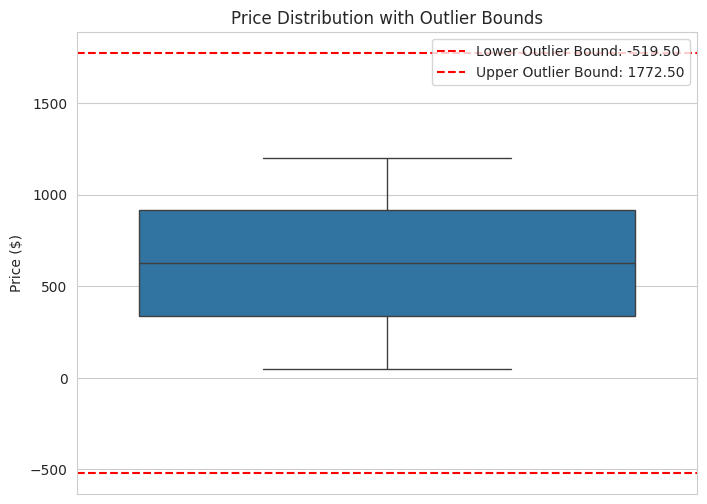

In [ ]:


plt.figure(figsize=(8, 6))
sns.boxplot(y=df_airbnb['price'])
plt.axhline(y=outlier_lower, color='r', linestyle='--', label=f'Lower Outlier Bound: {outlier_lower:.2f}')
plt.axhline(y=outlier_upper, color='r', linestyle='--', label=f'Upper Outlier Bound: {outlier_upper:.2f}')
plt.title('Price Distribution with Outlier Bounds')
plt.ylabel('Price ($)')
plt.legend()
plt.show()

## Rozkład typów nieruchomości
wykres słupkowy pokazujący liczebność każdej grupy typów nieruchomości

/tmp/ipykernel_2013/2352928.py:5: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  count_label = sns.barplot(x='Room Type',


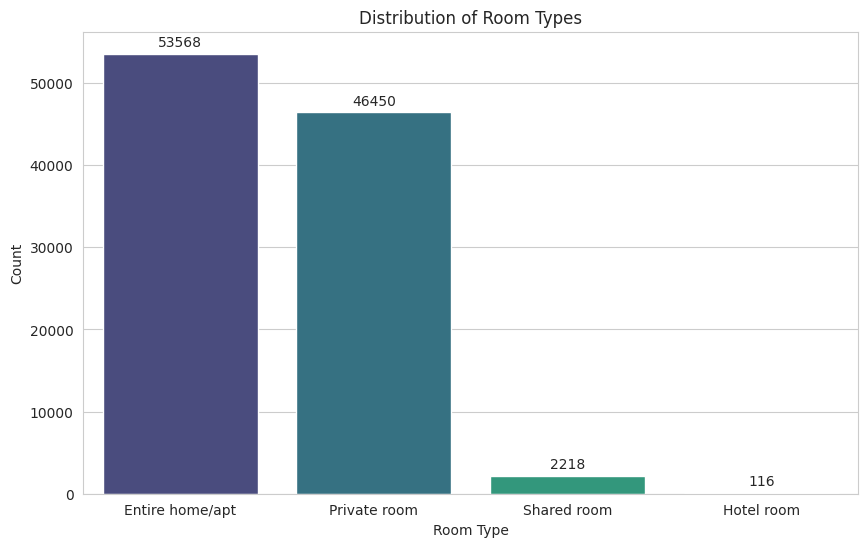

In [ ]:
room_type_counts = df_airbnb['room type'].value_counts().reset_index()
room_type_counts.columns = ['Room Type', 'Count']

plt.figure(figsize=(10, 6))
count_label = sns.barplot(x='Room Type',
            y='Count',
            data=room_type_counts,
            palette='viridis')
for container in count_label.containers:
    count_label.bar_label(container, padding=3)


plt.title('Distribution of Room Types')
plt.xlabel('Room Type')
plt.ylabel('Count')
plt.show()

## Rozkład ceny w zależności od dostępności
Wykres pudełkowy

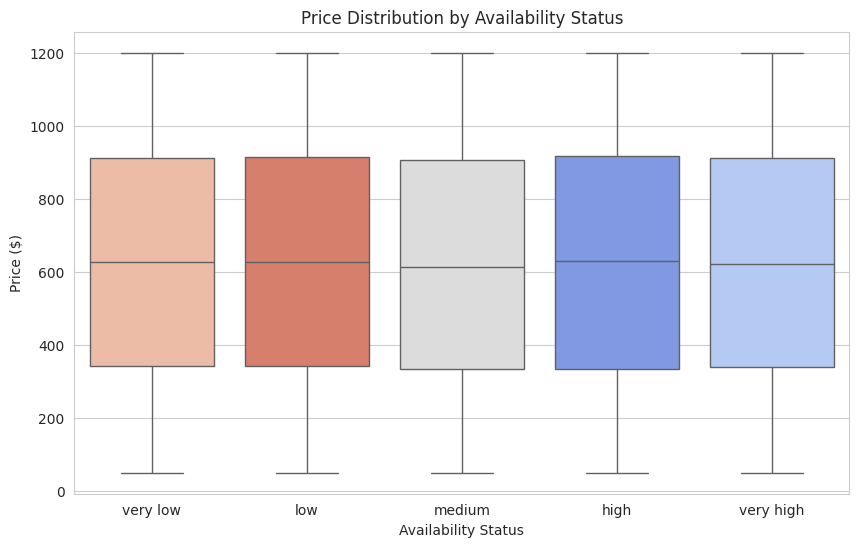

In [ ]:
plt.figure(figsize=(10, 6))
sns.boxplot(x='availability_status',
            y='price',
            data=df_airbnb, order=['very low', 'low', 'medium', 'high', 'very high'],
            hue = 'availability_status',
            palette = 'coolwarm')
plt.title('Price Distribution by Availability Status')
plt.xlabel('Availability Status')
plt.ylabel('Price ($)')
plt.show()

### Średnia cena dla roku budowy

wykres liniowy


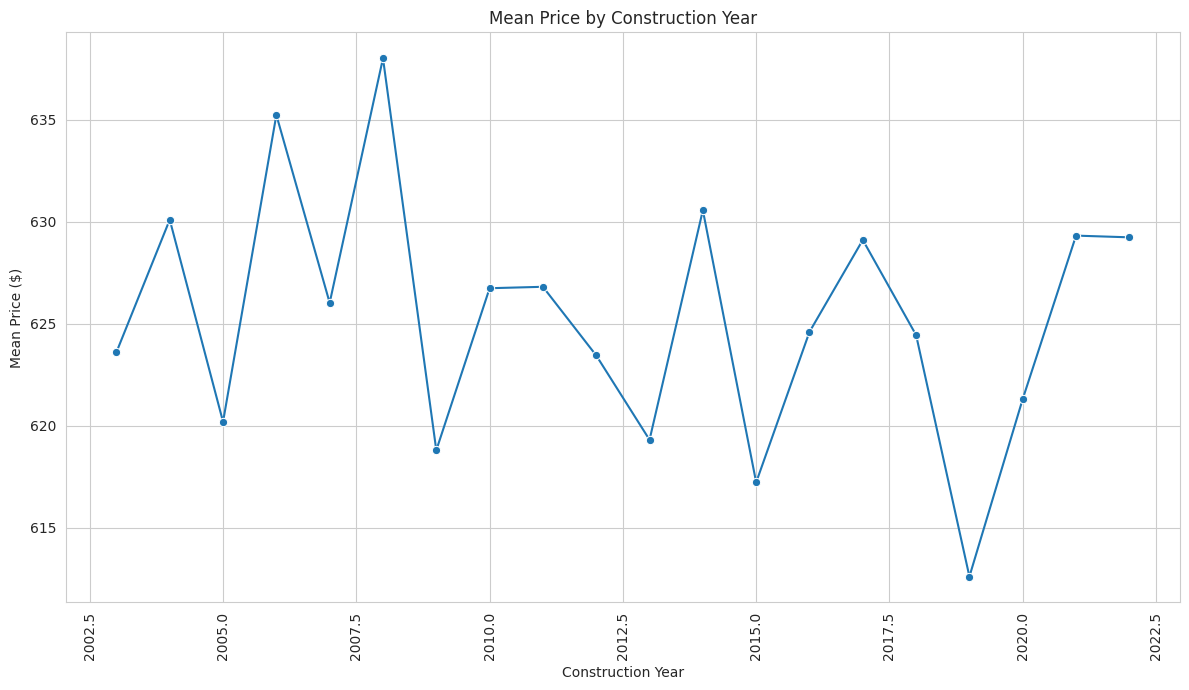

In [ ]:
plt.figure(figsize=(12, 7))
mean_price_by_year = df_airbnb.groupby('Construction year')['price'].mean().reset_index()
sns.lineplot(x='Construction year', y='price', data=mean_price_by_year, marker='o')
plt.title('Mean Price by Construction Year')
plt.xlabel('Construction Year')
plt.ylabel('Mean Price ($)')
plt.xticks(rotation=90)
plt.tight_layout()
plt.show()

### Średnia dostępność w zależności od roku budowy
Wykres liniowy

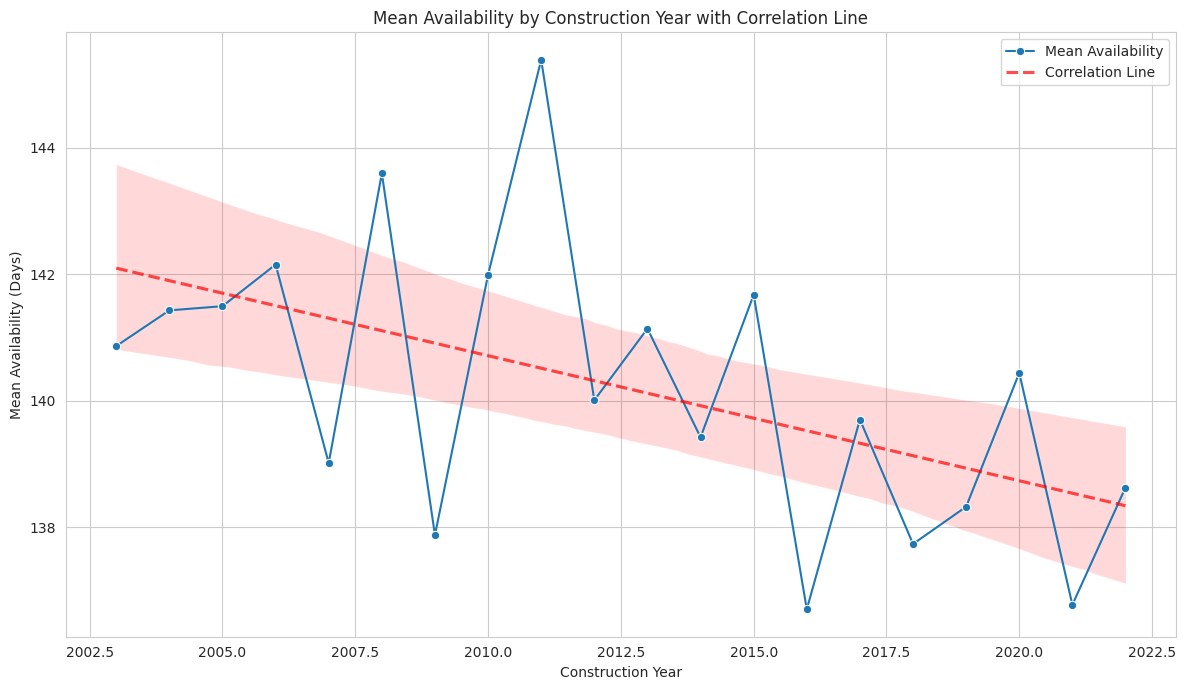

In [ ]:
plt.figure(figsize=(12, 7))
mean_availability_by_year = df_airbnb.groupby('Construction year')['availability 365'].mean().reset_index()
sns.lineplot(x='Construction year', y='availability 365', data=mean_availability_by_year, marker='o', label='Mean Availability')
sns.regplot(x='Construction year', y='availability 365', data=mean_availability_by_year, scatter=False, color='red', line_kws={'linestyle':'--', 'alpha':0.7}, label='Correlation Line')
plt.title('Mean Availability by Construction Year with Correlation Line')
plt.xlabel('Construction Year')
plt.ylabel('Mean Availability (Days)')
plt.legend()
plt.tight_layout()
plt.show()

### Średnia cena w poszczególnych dzielnicach
Wykres słupkowy

/tmp/ipykernel_2013/2923982690.py:2: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x='neighbourhood group',


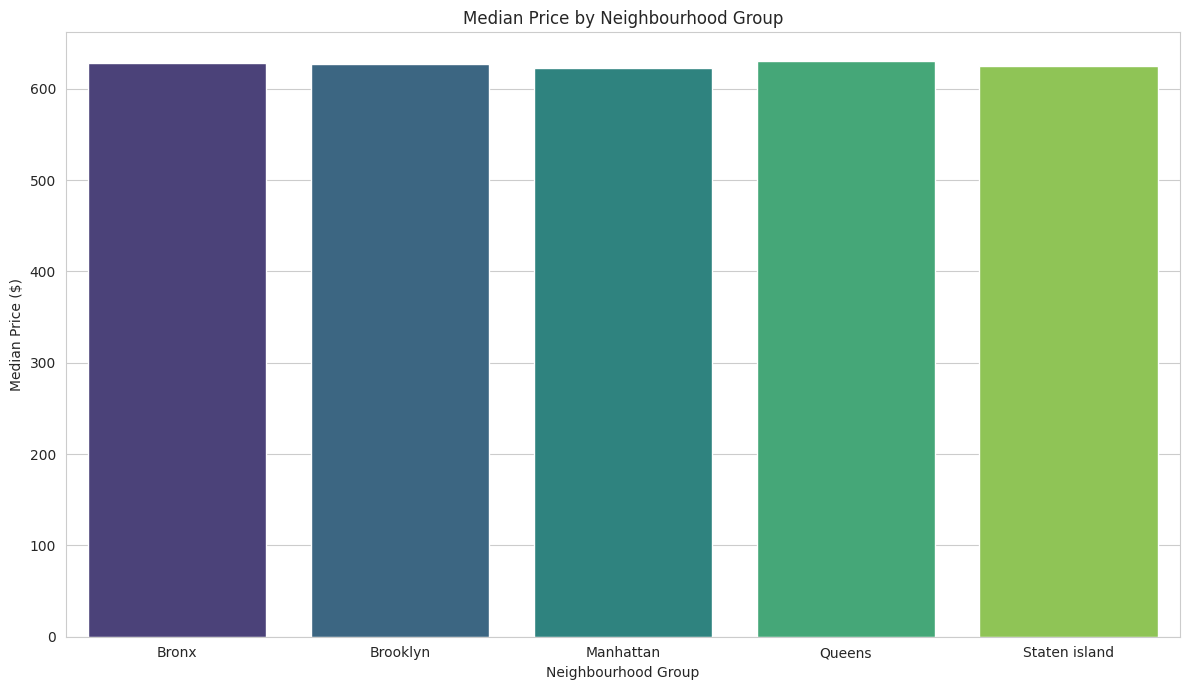

In [ ]:
plt.figure(figsize=(12, 7))
sns.barplot(x='neighbourhood group',
            y='price',
            data=df_airbnb,
            errorbar = None,
            order= ['Bronx',  'Brooklyn', 'Manhattan', 'Queens','Staten island'],
            palette='viridis')
plt.title('Median Price by Neighbourhood Group')
plt.xlabel('Neighbourhood Group')
plt.ylabel('Median Price ($)')

plt.tight_layout()
plt.show()

### Średnia dostępnośc w poszczególnych dzielnicach
Wykres słupkowy

/tmp/ipykernel_2013/62586351.py:2: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x='neighbourhood group',


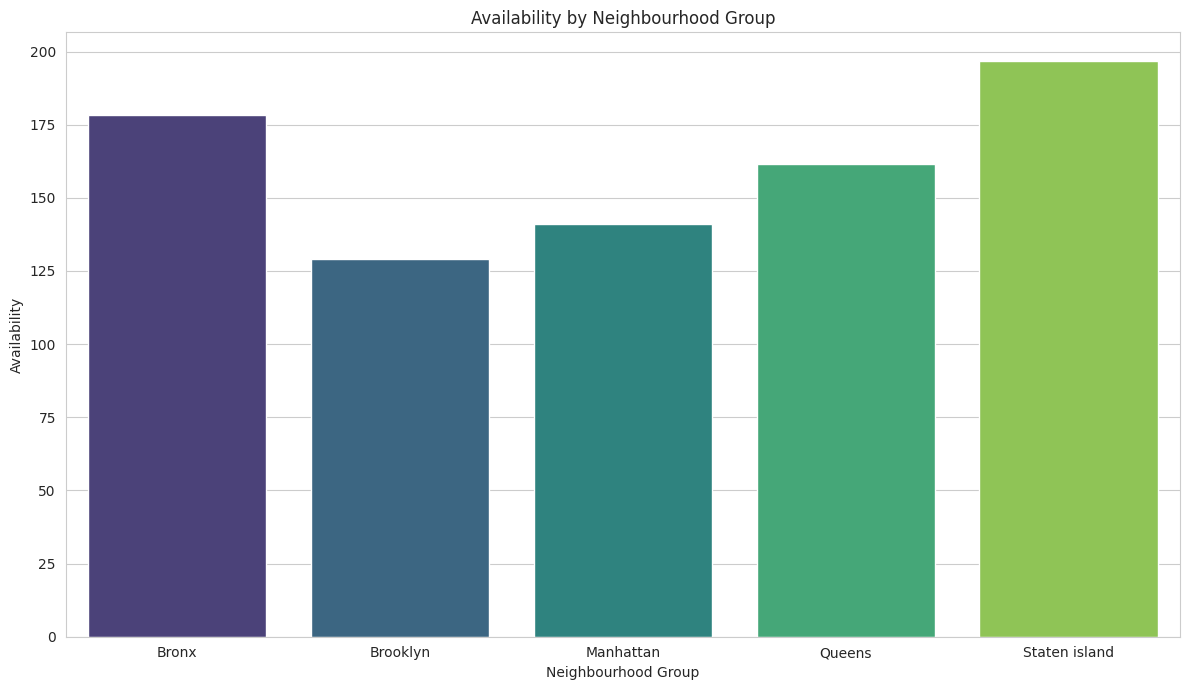

In [ ]:
plt.figure(figsize=(12, 7))
sns.barplot(x='neighbourhood group',
            y='availability 365',
            data=df_airbnb,
            errorbar = None,
            order= ['Bronx',  'Brooklyn', 'Manhattan', 'Queens','Staten island'],
            palette='viridis')
plt.title('Availability by Neighbourhood Group')
plt.xlabel('Neighbourhood Group')
plt.ylabel('Availability')
plt.tight_layout()
plt.show()

### Dystrybucja ceny zależnie od ocen danej nieruchomości
Wykres pudełkowy

/tmp/ipykernel_2013/2779796120.py:2: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(x='review rate number', y='price', data=df_airbnb, palette='coolwarm')


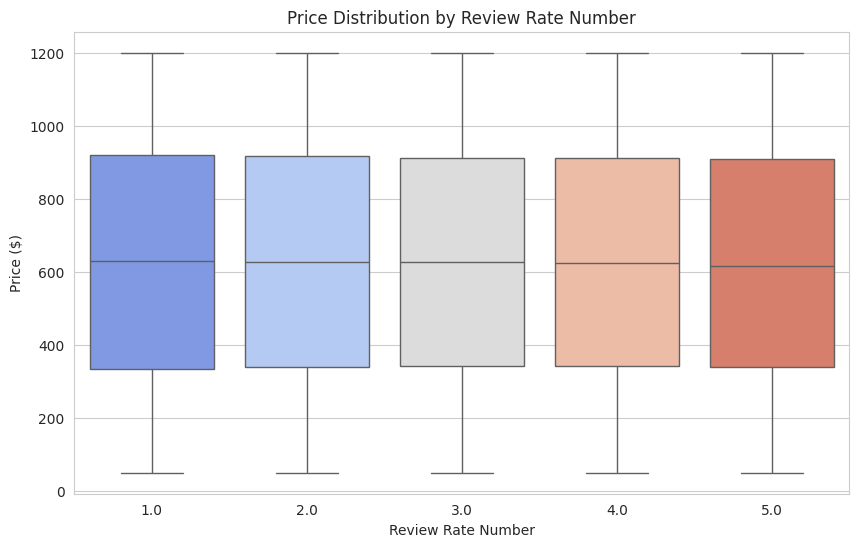

In [ ]:
plt.figure(figsize=(10, 6))
sns.boxplot(x='review rate number', y='price', data=df_airbnb, palette='coolwarm')
plt.title('Price Distribution by Review Rate Number')
plt.xlabel('Review Rate Number')
plt.ylabel('Price ($)')
plt.show()

### Dystrybucja dostępności zależnie od oceny
Wykres pudełkowy

/tmp/ipykernel_2013/1736138701.py:2: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(x='review rate number', y='availability 365', data=df_airbnb, palette='coolwarm')


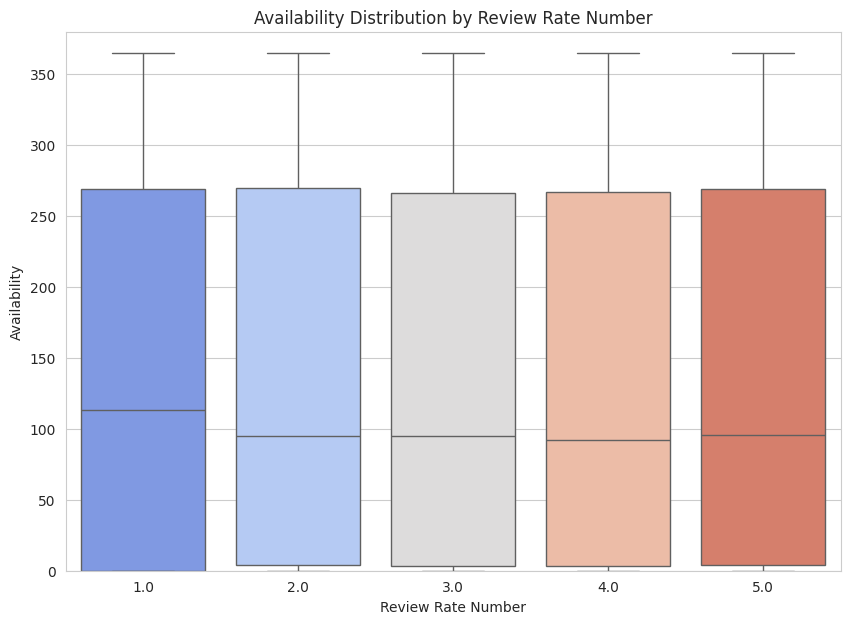

In [ ]:
plt.figure(figsize=(10, 7))
sns.boxplot(x='review rate number', y='availability 365', data=df_airbnb, palette='coolwarm')
plt.title('Availability Distribution by Review Rate Number')
plt.ylim(0,380)
plt.xlabel('Review Rate Number')
plt.ylabel('Availability')
plt.show()

### Rozkład ceny zależnie od typu nieruchomości
Wykres pudełkowy

/tmp/ipykernel_2013/1588123064.py:2: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(x='room type', y='price', data=df_airbnb, palette='coolwarm')


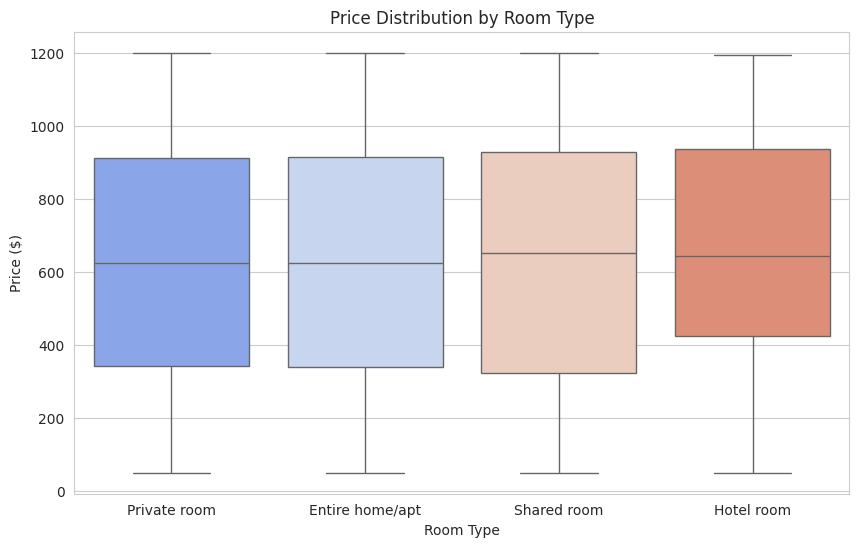

In [ ]:
plt.figure(figsize=(10, 6))
sns.boxplot(x='room type', y='price', data=df_airbnb, palette='coolwarm')
plt.title('Price Distribution by Room Type')
plt.xlabel('Room Type')
plt.ylabel('Price ($)')

plt.show()

### Rozkład dostępności dla typów nieruchomości
Wykres pudełkowy

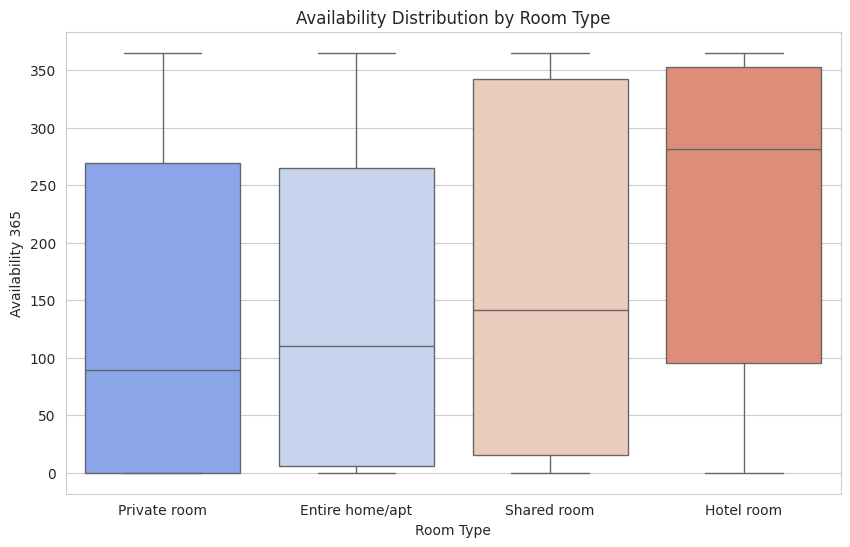

In [ ]:
plt.figure(figsize=(10,6))
sns.boxplot(x='room type',
            y='availability 365',
            hue='room type',
            data = df_airbnb,
            palette ='coolwarm'
             )
plt.title('Availability Distribution by Room Type')
plt.xlabel('Room Type')
plt.ylabel('Availability 365')
plt.show()

## Rozkład dostępności w zależności od okresu pobytu
wykres pudełkowy

<function matplotlib.pyplot.show(close=None, block=None)>

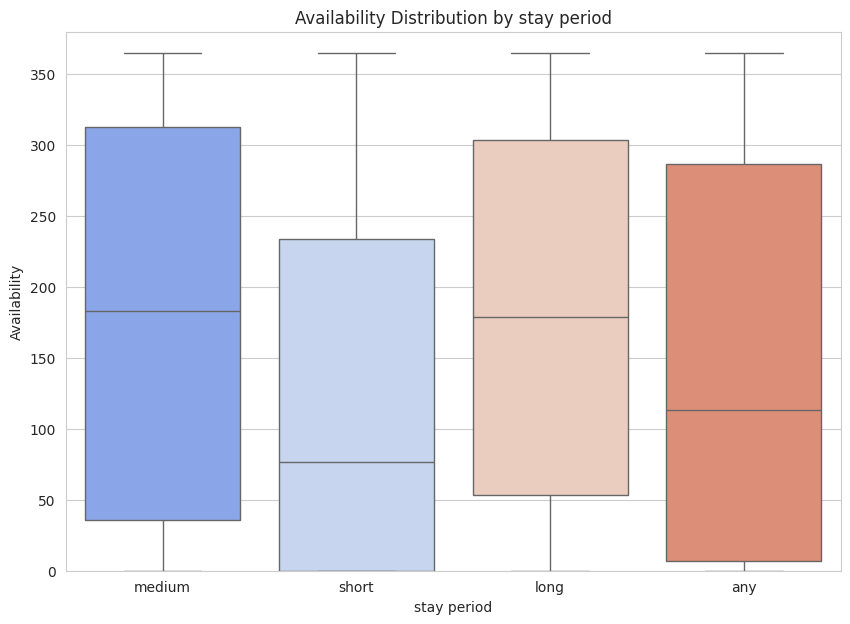

In [ ]:
plt.figure(figsize=(10,7))
sns.boxplot(
    x='stay_period',
    y ='availability 365',
    data=df_airbnb,
    hue = 'stay_period',
    palette = 'coolwarm')
plt.title('Availability Distribution by stay period')
plt.ylim(0,380)
plt.xlabel('stay period')
plt.ylabel('Availability')
plt.show()

## Rozkład ceny w zależności od czasu pobytu
Wykres pudełkowy

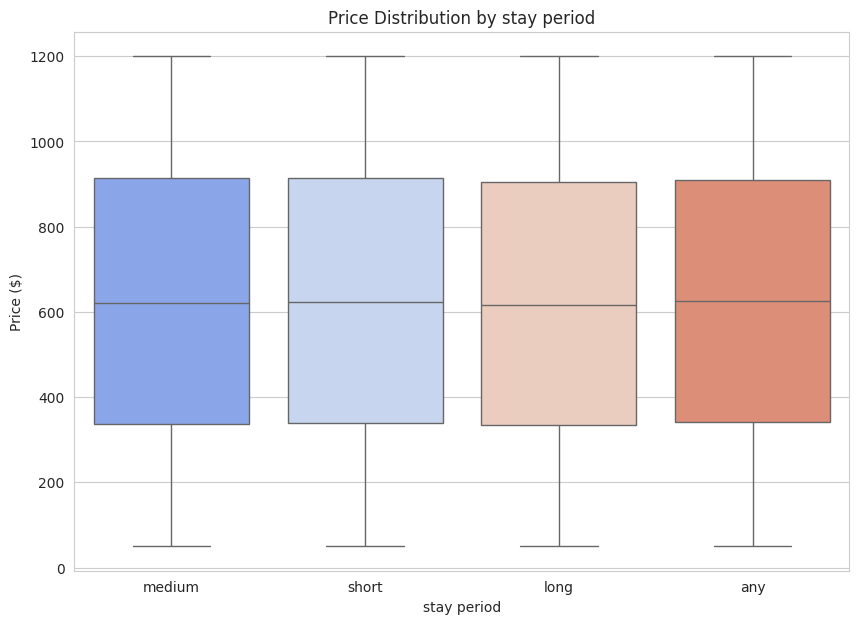

In [ ]:
plt.figure(figsize=(10,7))
sns.boxplot(
    x='stay_period',
    y ='price',
    data=df_airbnb,
    hue = 'stay_period',
    palette = 'coolwarm')
plt.title('Price Distribution by stay period')
plt.xlabel('stay period')
plt.ylabel('Price ($)')
plt.show()

## Dostępność danych typów nieruchomości w poszczególnych dzielnicach
Wykres słupkowy z liniami błedu

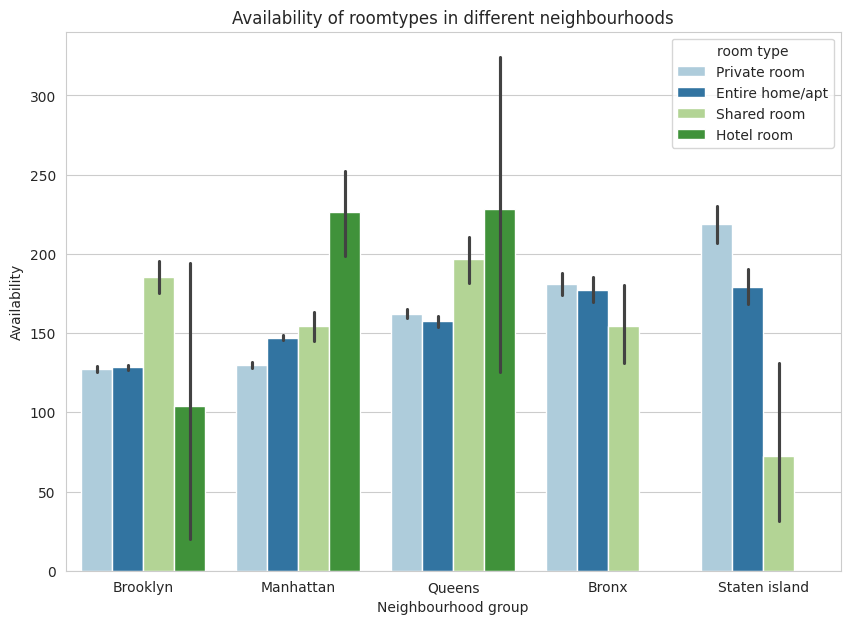

In [ ]:
plt.figure(figsize =(10,7))
sns.barplot(x= 'neighbourhood group',
            y= 'availability 365',
            hue = 'room type',
            palette = 'Paired',
            order = (['Brooklyn','Manhattan', 'Queens','Bronx', 'Staten island' ]),
            data= df_airbnb
            )
plt.title('Availability of roomtypes in different neighbourhoods')
plt.xlabel('Neighbourhood group')
plt.ylabel('Availability')
plt.show()

## Prognozowany przychód z inwestycji z podzaiłem na typy nieruchomości i dzielnice

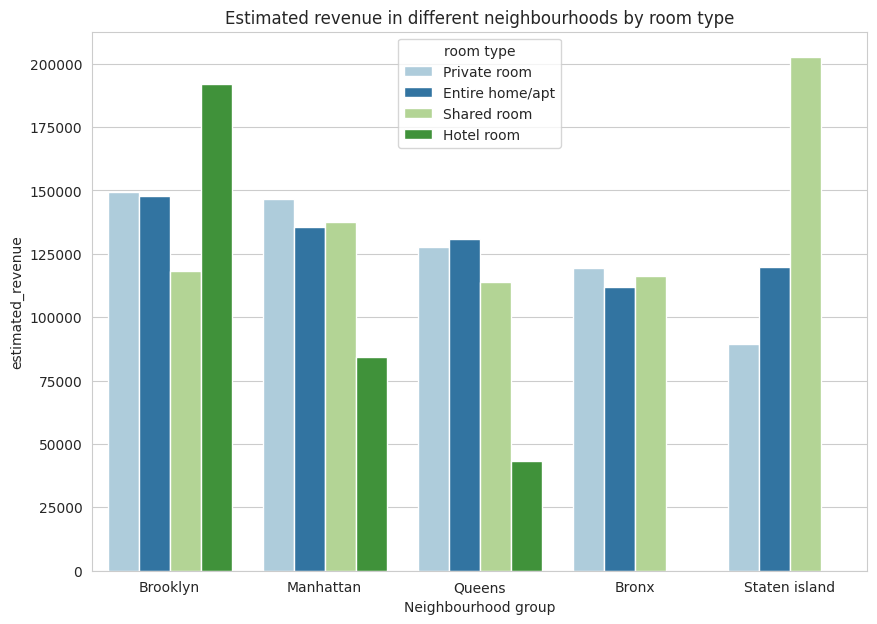

In [ ]:
plt.figure(figsize =(10,7))
sns.barplot(x= 'neighbourhood group',
            y = 'estimated_revenue',
            hue = 'room type',
            palette = 'Paired',
            order=(['Brooklyn','Manhattan', 'Queens','Bronx', 'Staten island' ]),
            data = df_airbnb,
            errorbar = None,
            legend = True,

            )
plt.title('Estimated revenue in different neighbourhoods by room type')
plt.xlabel('Neighbourhood group')
plt.ylabel('estimated_revenue')
plt.show()

### **Niewykorzystane analizy**

---



### dystrybucja ceny ze względu na rubrykę house rules (true)/(false)
Wykres pudełkowy przedstawiający dystrybucję ceny ze względu na posiadanie lub nieposiadanie zapisu o dodatkowych zasadach

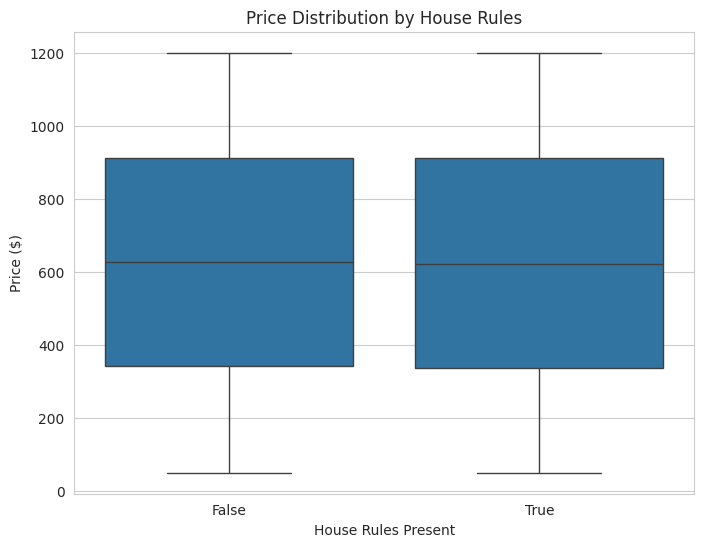

In [ ]:
plt.figure(figsize=(8, 6))
sns.boxplot(x='house_rules', y='price', data=df_airbnb)
plt.title('Price Distribution by House Rules')
plt.xlabel('House Rules Present')
plt.ylabel('Price ($)')
plt.show()

### dystrybucja dostępności ze względu na rubrykę house rules (true)/(false)
Wykres pudełkowy przedstawiający dystrybucję dostępności ze względu na posiadanie lub nieposiadanie zapisu o dodatkowych zasadach

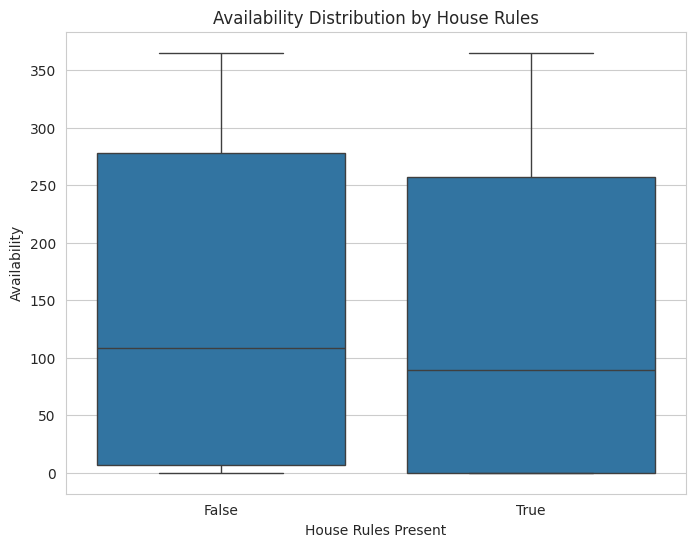

In [ ]:
plt.figure(figsize=(8, 6))
sns.boxplot(x='house_rules', y='availability 365', data=df_airbnb)
plt.title('Availability Distribution by House Rules')
plt.xlabel('House Rules Present')
plt.ylabel('Availability')
plt.show()

### Dystrybucja ceny W zaeżności od polityki anulacji

/tmp/ipykernel_2013/2204691016.py:2: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(x='cancellation_policy', y='price', data=df_airbnb, palette='RdYlGn')


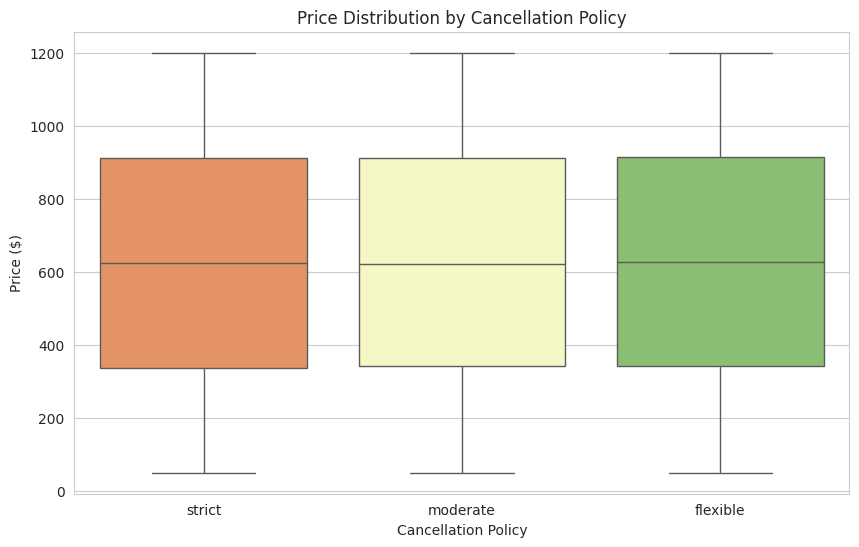

In [ ]:
plt.figure(figsize=(10, 6))
sns.boxplot(x='cancellation_policy', y='price', data=df_airbnb, palette='RdYlGn')
plt.title('Price Distribution by Cancellation Policy')
plt.xlabel('Cancellation Policy')
plt.ylabel('Price ($)')

plt.show()

/tmp/ipykernel_2013/1617349488.py:2: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(x='cancellation_policy', y='availability 365', data=df_airbnb, palette='RdYlGn')


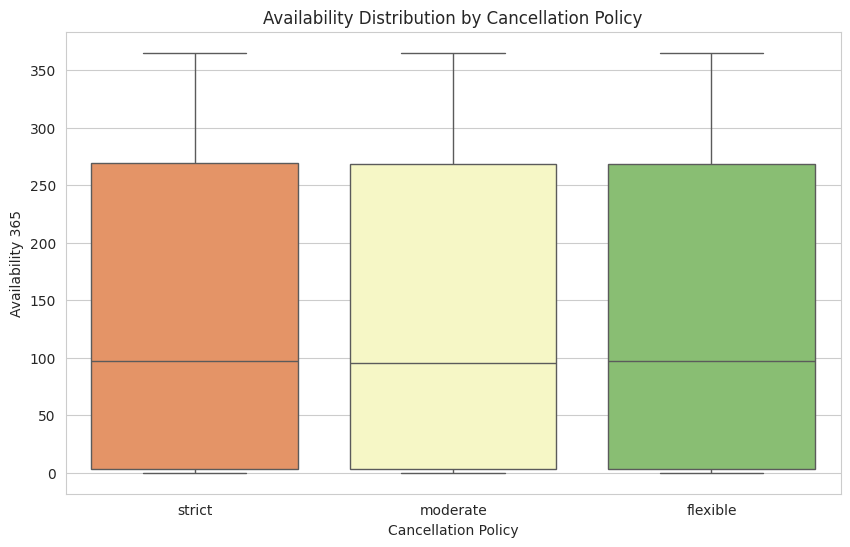

In [ ]:
plt.figure(figsize=(10, 6))
sns.boxplot(x='cancellation_policy', y='availability 365', data=df_airbnb, palette='RdYlGn')
plt.title('Availability Distribution by Cancellation Policy')
plt.xlabel('Cancellation Policy')
plt.ylabel('Availability 365')
plt.show()

/tmp/ipykernel_2013/3264910778.py:2: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(x='instant_bookable', y='price', data=df_airbnb, palette='pastel')


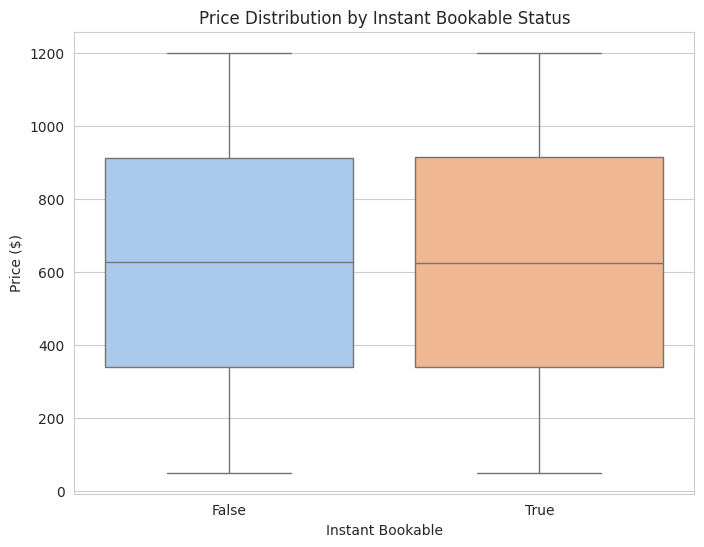

In [ ]:
plt.figure(figsize=(8, 6))
sns.boxplot(x='instant_bookable', y='price', data=df_airbnb, palette='pastel')
plt.title('Price Distribution by Instant Bookable Status')
plt.xlabel('Instant Bookable')
plt.ylabel('Price ($)')
plt.show()

/tmp/ipykernel_2013/2917956218.py:2: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(x='instant_bookable', y='availability 365', data=df_airbnb, palette='pastel')


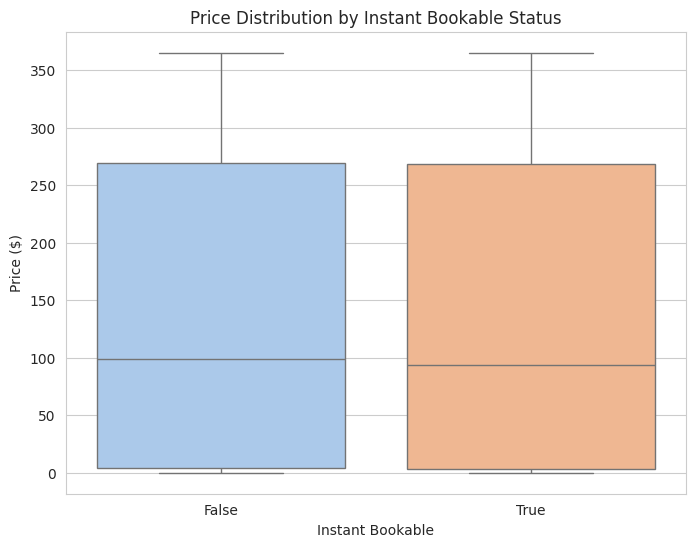

In [ ]:
plt.figure(figsize=(8, 6))
sns.boxplot(x='instant_bookable', y='availability 365', data=df_airbnb, palette='pastel')
plt.title('Price Distribution by Instant Bookable Status')
plt.xlabel('Instant Bookable')
plt.ylabel('Price ($)')
plt.show()

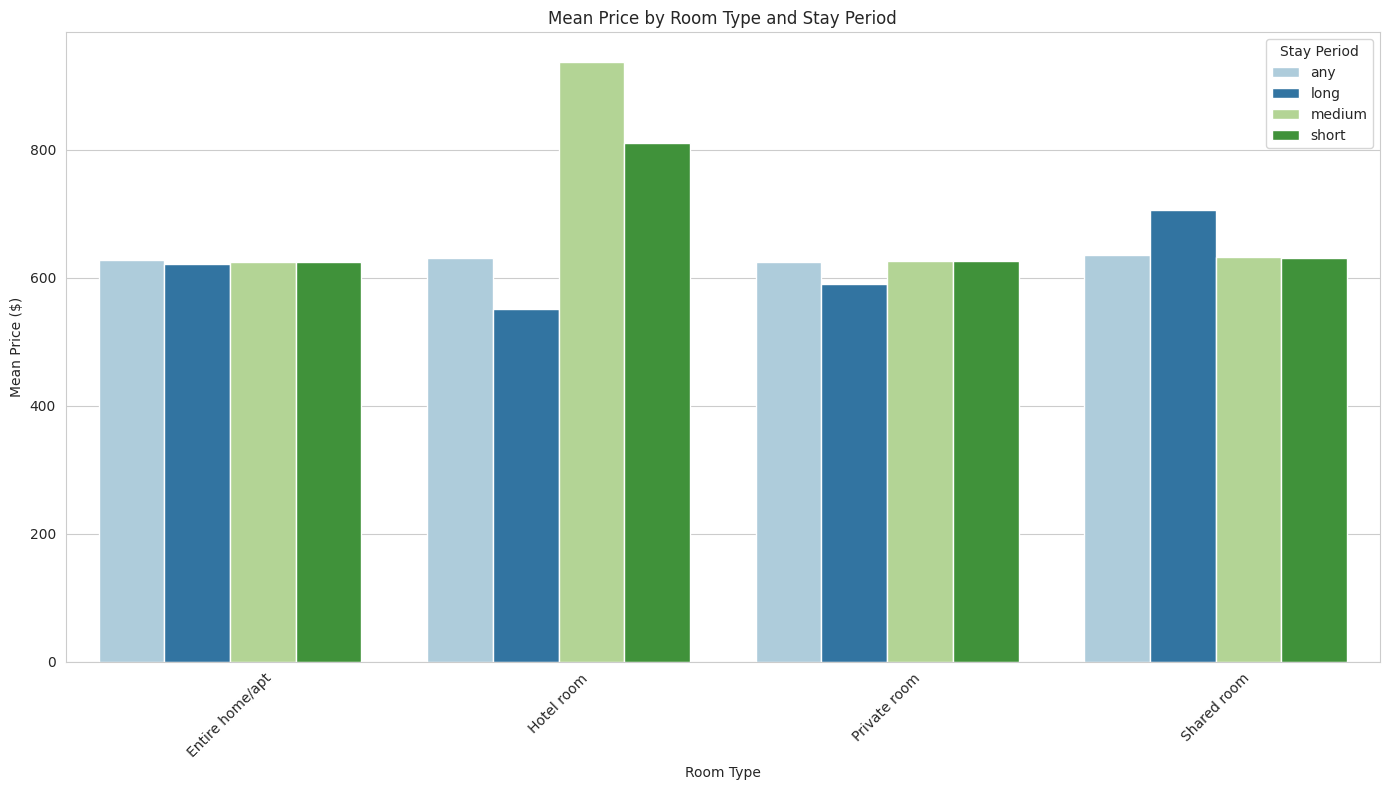

In [ ]:
plt.figure(figsize=(14, 8))
mean_price_room_stay = df_airbnb.groupby(['room type', 'stay_period'])['price'].mean().reset_index()
sns.barplot(x='room type', y='price', hue='stay_period', data=mean_price_room_stay, palette='Paired')
plt.title('Mean Price by Room Type and Stay Period')
plt.xlabel('Room Type')
plt.ylabel('Mean Price ($)')
plt.legend(title='Stay Period')
plt.tight_layout()
plt.show()